In [810]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [811]:
df = pd.read_excel("Logistics_Delivery_Cleaned.xlsx")

# 1. Calculate daily shipment volume by origin, destination zone, carrier, and service level.

In [812]:
df['Booking_Date'] = pd.to_datetime(
    df['Booking_Date'],
    format='mixed',
    errors='coerce'#it converts the invalid dates into Nat
)

In [813]:
daily_volume = df.groupby(
    ['Origin', 'Destination_Zone', 'Carrier_Name', 'Service_Level']
)['Shipment_ID'].nunique().reset_index(name='Daily_Shipment_Count')#nunique(In how many different shipments
#did repeat attempts occur?)

daily_volume.head(5)

,Origin,Destination_Zone,Carrier_Name,Service_Level,Daily_Shipment_Count
0,WH-E,BBSR-751001,GREEN LINE,STD,1
1,WH-E,BBSR-751001,SWIFT POST,ECO,1
2,WH-E,BER-760001,ROADX,EXP,1
3,WH-E,Berhampur 760001,FASTSHIP,STD,1
4,WH-E,Berhampur 760001,GREEN LINE,ECO,1


# 2. Measure on-time pickup, on-time delivery, and delivery-in-full rates against promised windows.

In [814]:
cols = [
    'Promised_Pickup_Timestamp',
    'Pickup_Timestamp',
    'Promised_Delivery_Start',
    'Promised_Delivery_End',
    'Actual_Delivery_Timestamp',
    'Delivery_Quantity',
    'Order_Quantity'
]
for i in cols:
    df[i]=pd.to_datetime(df[i],format='mixed',errors='coerce')
df[cols].dtypes

C:\Users\HP\AppData\Local\Temp\ipykernel_10868\4007415952.py:11: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df[i]=pd.to_datetime(df[i],format='mixed',errors='coerce')


Promised_Pickup_Timestamp    datetime64[ns, UTC+05:30]
Pickup_Timestamp                                object
Promised_Delivery_Start      datetime64[ns, UTC+05:30]
Promised_Delivery_End        datetime64[ns, UTC+05:30]
Actual_Delivery_Timestamp          datetime64[ns, UTC]
Delivery_Quantity                       datetime64[ns]
Order_Quantity                          datetime64[ns]
dtype: object

In [815]:
df['Delivery_Quantity'] = pd.to_numeric(
    df['Delivery_Quantity'], errors='coerce'
)

df['Order_Quantity'] = pd.to_numeric(
    df['Order_Quantity'], errors='coerce'
)

print(df[['Delivery_Quantity', 'Order_Quantity']].dtypes)

Delivery_Quantity    int64
Order_Quantity       int64
dtype: object


In [816]:
df['On_Time_Pickup'] = (
    df['Pickup_Timestamp'] <= df['Promised_Pickup_Timestamp']
)
pickup_rate = df['On_Time_Pickup'].mean() * 100
print("On-time Pickup Rate:", round(pickup_rate, 2), "%")

On-time Pickup Rate: 79.6 %


In [817]:
df['On_Time_Delivery_Calc'] = (
    (df['Actual_Delivery_Timestamp'] >= df['Promised_Delivery_Start']) &
    (df['Actual_Delivery_Timestamp'] <= df['Promised_Delivery_End'])
)
delivery_rate = df['On_Time_Delivery_Calc'].mean() * 100

print("On-time Delivery Rate:", round(delivery_rate, 2), "%")

On-time Delivery Rate: 6.26 %


In [818]:
df['Delivered_In_Full'] = (
    df['Delivery_Quantity'] >= df['Order_Quantity']
)

full_rate = df['Delivered_In_Full'].mean() * 100

print("Delivery-in-Full Rate:", round(full_rate, 2), "%")


Delivery-in-Full Rate: 100.0 %


# 3. Calculate transit time and warehouse dwell time between defined scan milestones.

In [819]:
date_cols = [
    'Pickup_Timestamp',
    'Actual_Delivery_Timestamp',
    'Warehouse_Arrival_Timestamp',
    'Warehouse_Departure_Timestamp'
]

for col in date_cols:
    df[col] = pd.to_datetime(
        df[col], errors='coerce', format='mixed'
    )


C:\Users\HP\AppData\Local\Temp\ipykernel_10868\1268514220.py:9: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df[col] = pd.to_datetime(


In [820]:
df['Transit_Time_Hours_Calc'] = (
    df['Actual_Delivery_Timestamp'] -
    df['Pickup_Timestamp']
).dt.total_seconds() / 3600

In [821]:
df["Warehouse_Arrival_Timestamp"] = pd.to_datetime(
    df["Warehouse_Arrival_Timestamp"], format="mixed", errors="coerce", utc=True
)

df["Warehouse_Departure_Timestamp"] = pd.to_datetime(
    df["Warehouse_Departure_Timestamp"], format="mixed", errors="coerce", utc=True
)

df["Warehouse_Dwell_Time_Hours"] = (
    df["Warehouse_Departure_Timestamp"] -
    df["Warehouse_Arrival_Timestamp"]
).dt.total_seconds() / 3600

print(df["Warehouse_Dwell_Time_Hours"].describe().round(2))

count    101.0
mean       3.0
std        0.0
min        3.0
25%        3.0
50%        3.0
75%        3.0
max        3.0
Name: Warehouse_Dwell_Time_Hours, dtype: float64


In [822]:
print(df[[
    'Shipment_ID',
    'Transit_Time_Hours_Calc',
    'Warehouse_Dwell_Time_Hours'
]].head())

  Shipment_ID  Transit_Time_Hours_Calc  Warehouse_Dwell_Time_Hours
0  SHP-100001               103.233333                         NaN
1  SHP-100001                      NaN                         NaN
2  SHP-100001                      NaN                         NaN
3  SHP-100001                      NaN                         NaN
4  SHP-100001                      NaN                         3.0


# 4. Build first-attempt delivery success and repeat-attempt metrics.

In [823]:
df['Warehouse_Arrival_Timestamp'] = pd.to_datetime(
    df['Warehouse_Arrival_Timestamp'],
    errors='coerce',
    format='mixed'
)

df['Warehouse_Departure_Timestamp'] = pd.to_datetime(
    df['Warehouse_Departure_Timestamp'],
    errors='coerce',
    format='mixed'
)
print(df['Attempt_Status'].value_counts(dropna=False))
print(df['First_Attempt_Delivery_Flag'].value_counts(dropna=False))
print(df['Delivery_Attempt_Count'].value_counts(dropna=False))

Attempt_Status
Unknown            309
SUCCESS             61
IN_PROGRESS         47
  SUCCESS           10
 IN_PROGRESS        10
  IN_PROGRESS        9
Success              8
in_progress          8
In_Progress          7
success              6
 SUCCESS             6
IN_PROGRESS          6
FAILED               4
SUCCESS              2
failed               1
Failed               1
Name: count, dtype: int64
First_Attempt_Delivery_Flag
NaN      396
Y         18
1         17
TRUE      17
Yes       13
y         11
yes       11
No         5
N          3
n          2
0          1
FALSE      1
Name: count, dtype: int64
Delivery_Attempt_Count
NaN    309
1.0    174
2.0     12
Name: count, dtype: int64


In [824]:
df['Attempt_Status'] = (
    df['Attempt_Status']
    .astype('string')
    .str.strip()
    .str.upper()
)

df['First_Attempt_Delivery_Flag'] = (
    df['First_Attempt_Delivery_Flag']
    .astype('string')
    .str.strip()
    .str.upper()
)


print(df['Attempt_Status'].value_counts(dropna=False))
print(df['First_Attempt_Delivery_Flag'].value_counts(dropna=False))


Attempt_Status
UNKNOWN        309
SUCCESS         93
IN_PROGRESS     87
FAILED           6
Name: count, dtype: Int64
First_Attempt_Delivery_Flag
<NA>     396
Y         29
YES       24
TRUE      17
1         17
NO         5
N          5
0          1
FALSE      1
Name: count, dtype: Int64


In [825]:
flag = (
    df['First_Attempt_Delivery_Flag']
    .astype('string')
    .str.strip()
    .str.upper()
)

df['First_Attempt_Success'] = flag.map({
    'Y': True,
    'YES': True,
    'TRUE': True,
    '1': True,
    'N': False,
    'NO': False,
    'FALSE': False,
    '0': False
})
print(df['First_Attempt_Success'].value_counts(dropna=False))

First_Attempt_Success
NaN      396
True      87
False     12
Name: count, dtype: int64


In [826]:
valid_first = df[df['First_Attempt_Success'].notna()]

first_attempt_rate = (
    valid_first['First_Attempt_Success'].mean() * 100
)

print("First-Attempt Delivery Success Rate:",
      round(first_attempt_rate, 2),"%")

First-Attempt Delivery Success Rate: 87.88 %


In [827]:
valid_attempts = df[df['Delivery_Attempt_Count'].notna()]

repeat_attempts = valid_attempts[
    valid_attempts['Delivery_Attempt_Count'] > 1
]

print("Shipments/records with repeat attempts:", len(repeat_attempts))

Shipments/records with repeat attempts: 12


In [828]:
repeat_shipment_count = repeat_attempts['Shipment_ID'].nunique()

print("Unique shipments with repeat attempts:", repeat_shipment_count)

Unique shipments with repeat attempts: 6


# 5. Measure exception rates by reason, carrier, depot, and delivery zone.

In [829]:

df["Exception_Flag"] = df["Exception_Flag"].astype(str).str.lower().isin(["yes", "y", "true", "1"])

ship = df.groupby("Shipment_ID").agg({
    "Exception_Flag": "max",
    "Exception_Reason": "first",
    "Carrier_Name": "first",
    "Depot_Name": "first",
    "Delivery_Zone": "first"
}).reset_index()

for col in ["Carrier_Name", "Depot_Name", "Delivery_Zone"]:
    rate = ship.groupby(col)["Exception_Flag"].mean() * 100
    print(f"\nException Rate by {col}:")
    print(rate.sort_values(ascending=False).round(2))

reason = ship[ship["Exception_Flag"]].groupby("Exception_Reason")["Shipment_ID"].count()
print("\nException Rate by Reason:")
print((reason / ship["Shipment_ID"].nunique() * 100).round(2))




Exception Rate by Carrier_Name:
Carrier_Name
SWIFT POST    28.57
ROADX         13.33
SWIFTPOST     10.53
FASTSHIP       0.00
GREEN LINE     0.00
GREEN-LINE     0.00
ROAD-X         0.00
ROAD X         0.00
GREENLINE      0.00
SWIFT-POST     0.00
Name: Exception_Flag, dtype: float64

Exception Rate by Depot_Name:
Depot_Name
BHUBANESWAR DEPOT    15.00
CUTTACK DEPOT        11.11
ROURKELA DEPOT        8.33
PURI DEPOT            5.88
BERHAMPUR DEPOT       0.00
SAMBALPUR DEPOT       0.00
Name: Exception_Flag, dtype: float64

Exception Rate by Delivery_Zone:
Delivery_Zone
ROURKELA 769001       33.33
BHUBANESWAR 751001    14.29
BBSR-751001           13.33
CTC-753001            12.50
PURI 752001           12.50
BER-760001             0.00
BERHAMPUR 760001       0.00
CUTTACK 753001         0.00
PURI-752001            0.00
RKL-769001             0.00
SAMBALPUR 768001       0.00
SBP-768001             0.00
Name: Exception_Flag, dtype: float64

Exception Rate by Reason:
Exception_Reason
address inc

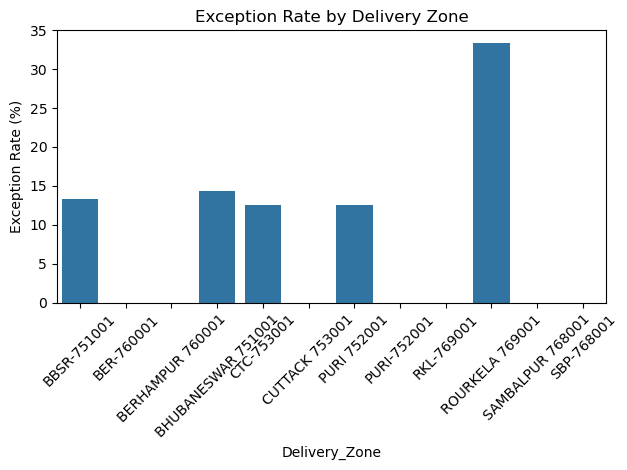

In [830]:
sns.barplot(x=rate.index, y=rate.values)
plt.xticks(rotation=45)
plt.ylabel("Exception Rate (%)")
plt.title("Exception Rate by Delivery Zone")
plt.tight_layout()
plt.show()

# 6. Calculate route adherence and stop completion rates where planned routes are available.

In [831]:

df["Completed_Stop_Count"] = pd.to_numeric(df["Completed_Stop_Count"], errors="coerce")
df["Planned_Stop_Count"] = pd.to_numeric(df["Planned_Stop_Count"], errors="coerce")


df["Route_Match"] = df["Route_ID"] == df["Planned_Route_ID"]
print("Route Adherence:", round(df["Route_Match"].mean() * 100, 2), "%")


completed = df["Completed_Stop_Count"].sum()
planned = df["Planned_Stop_Count"].sum()

print("Stop Completion:", round(completed / planned * 100, 2), "%")

Route Adherence: 13.94 %
Stop Completion: 54.8 %


# 7. Summarize shipment cost, surcharge, claim cost, and cost per delivered parcel.

In [832]:

cost = df.groupby("Shipment_ID").agg({
    "Freight_Charge": "max",
    "Surcharge_Amount": "max",
    "Claim_Amount": "max",
    "Parcel_Status": lambda x: x.str.strip().str.lower().eq("delivered").any()
})

print("Shipment Cost:", cost["Freight_Charge"].sum())
print("Total Surcharge:", cost["Surcharge_Amount"].sum())
print("Claim Cost: Not available")

delivered = cost["Parcel_Status"].sum()
print("Cost per Delivered Parcel:",
      (cost["Freight_Charge"].sum() + cost["Surcharge_Amount"].sum()) / delivered)

Shipment Cost: 48640.87
Total Surcharge: 1285.0
Claim Cost: Not available
Cost per Delivered Parcel: 536.837311827957


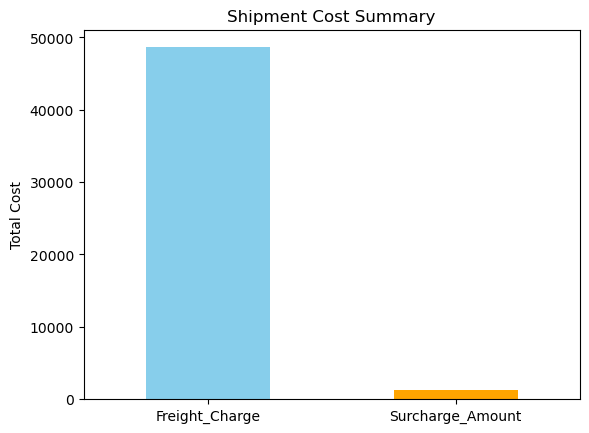

In [833]:

cost[["Freight_Charge", "Surcharge_Amount"]].sum().plot(
    kind="bar", color=["skyblue", "orange"]
)

plt.title("Shipment Cost Summary")
plt.ylabel("Total Cost")
plt.xticks(rotation=0)
plt.show()

# 8. Build volume and delay heatmaps by depot and time window.

In [834]:

volume = df.pivot_table(
    index="Depot_Name",
    columns="Time_Window",
    values="Shipment_ID",
    aggfunc="nunique",
    fill_value=0
)

print("Shipment Volume:")
print(volume)

Shipment Volume:
Time_Window        -  03-06  06-09  09-12  12-15  15-18  ?
Depot_Name                                                
BERHAMPUR DEPOT    0      0     17      2      4      9  0
BHUBANESWAR DEPOT  1      0     20      4      5     10  0
CUTTACK DEPOT      1      0      9      0      2      5  0
PURI DEPOT         1      1     15      3      7      3  0
ROURKELA DEPOT     0      0     11      2      4      1  1
SAMBALPUR DEPOT    0      0     16      4      5      8  1


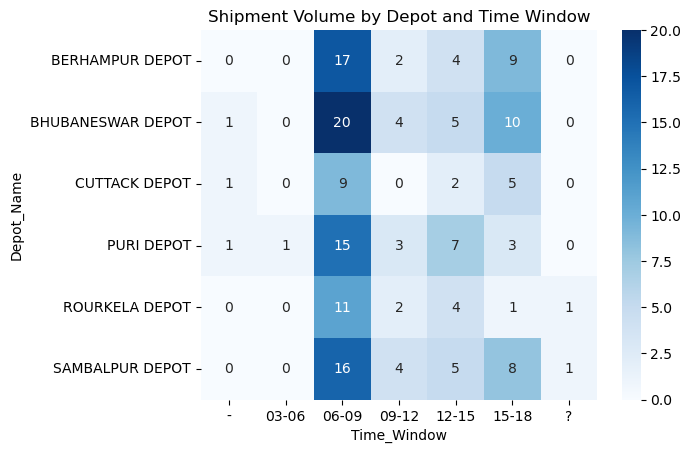

In [835]:
sns.heatmap(volume, annot=True, fmt=".0f", cmap="Blues")
plt.title("Shipment Volume by Depot and Time Window")
plt.show()

In [836]:

df["Actual"] = pd.to_datetime(df["Actual_Delivery_Timestamp"], format="mixed", utc=True, errors="coerce")
df["Promised"] = pd.to_datetime(df["Promised_Delivery_Timestamp"], format="mixed", utc=True, errors="coerce")

df["Delay"] = (df["Actual"] - df["Promised"]).dt.total_seconds() / 60

delay = df.pivot_table(
    index="Depot_Name", columns="Time_Window",
    values="Delay", aggfunc="mean"
)

print(delay.round(2))

Time_Window            -   06-09    09-12   12-15    15-18      ?
Depot_Name                                                       
BERHAMPUR DEPOT      NaN     NaN  -513.00 -1159.5  -930.50    NaN
BHUBANESWAR DEPOT    NaN     NaN -1487.67   287.5  -188.71    NaN
CUTTACK DEPOT     -444.0     NaN      NaN  -326.0  -206.33    NaN
PURI DEPOT           NaN     NaN -1258.50  -410.0  -186.67    NaN
ROURKELA DEPOT       NaN -3596.0  -523.00   265.5      NaN -187.0
SAMBALPUR DEPOT      NaN     NaN  -558.75   685.5 -1123.67    NaN


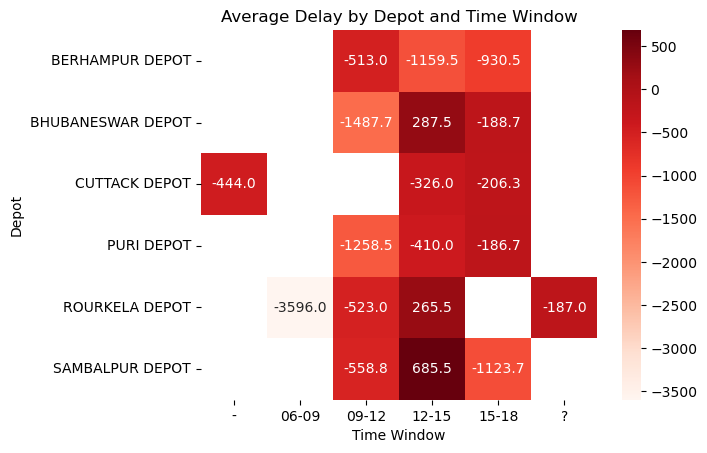

In [837]:
sns.heatmap(delay, annot=True, fmt=".1f", cmap="Reds")
plt.title("Average Delay by Depot and Time Window")
plt.xlabel("Time Window")
plt.ylabel("Depot")
plt.show()

# 9. Measure scan compliance and missing-event rates by carrier.

In [838]:
df['Missing_Events'] = (
    df['Expected_Scan_Count'] - df['Actual_Scan_Count']
).clip(lower=0)

In [839]:
result = df.groupby('Carrier_Name')['Missing_Events'].sum()
print(result)

Carrier_Name
FASTSHIP       0
GREEN LINE    12
GREEN-LINE     6
GREENLINE      6
ROAD X         4
ROAD-X         2
ROADX         14
SWIFT POST     0
SWIFT-POST     0
SWIFTPOST      6
Name: Missing_Events, dtype: int64


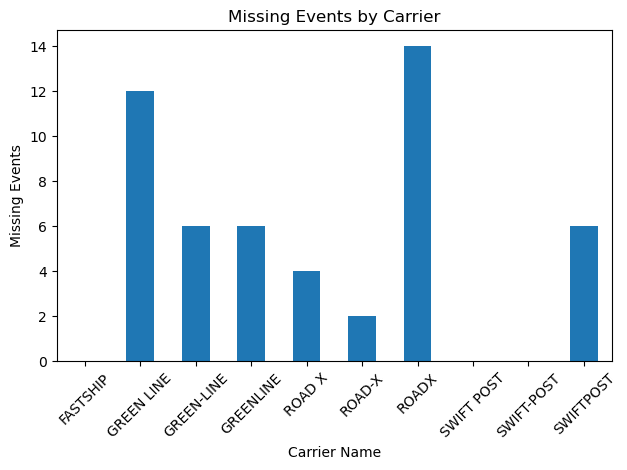

In [840]:
result.plot(kind='bar')
plt.title("Missing Events by Carrier")
plt.xlabel("Carrier Name")
plt.ylabel("Missing Events")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 10. Calculate damage, loss, and return-to-sender rates.

--Note--
* getting 0.0% because the values in Parcel_Status may not exactly match "Damaged", "Lost", or "Return to Sender".

In [841]:
total = df["Shipment_ID"].nunique()

for status in ["Damaged", "Lost", "Return to Sender"]:
    count = df.loc[
        df["Parcel_Status"].astype(str).str.strip().str.lower() == status.lower(),
        "Shipment_ID"
    ].nunique()

    rate = (count / total * 100) if total else 0

    print(f"{status} Shipments: {count}")
    print(f"{status} Rate: {rate:.2f}%")

Damaged Shipments: 0
Damaged Rate: 0.00%
Lost Shipments: 0
Lost Rate: 0.00%
Return to Sender Shipments: 0
Return to Sender Rate: 0.00%


In [842]:
print(df.columns.tolist())

['Shipment_ID', 'Shipment_Status', 'Shipment_Type', 'Shipment_Date', 'Shipment_Volume', 'Shipment_Event_ID', 'Ordinal_Shipment_ID', 'Return_Shipment_ID', 'Return_To_Sender_Flag', 'Tracking_ID', 'Parcel_ID', 'Parcel_Count', 'Parcel_Weight', 'Parcel_Volume', 'Parcel_Status', 'Package_Weight', 'Weight', 'Weight_Unit', 'Length', 'Width', 'Height', 'Dimension_Unit', 'Declared_Value', 'Carrier_ID', 'Carrier_Name', 'Carrier_Alias', 'Service_Type', 'Service_Level', 'Booking_Date', 'Booking_Weekday', 'Pickup_Timestamp', 'Actual_Delivery_Timestamp', 'Delivery_Timestamp', 'Promised_Delivery_Date', 'Promised_Delivery_Timestamp', 'Promised_Pickup_Timestamp', 'Promised_Delivery_Start', 'Promised_Delivery_End', 'Delivery_Attempt_Count', 'Delivery_Attempt_ID', 'Delivery_Attempt_Number', 'First_Attempt_Timestamp', 'First_Attempt_Delivery_Flag', 'First_Attempt_Status', 'Attempt_Number', 'Attempt_Status', 'Attempt_Timestamp', 'Delivery_Success_Flag', 'On_Time_Delivery_Flag', 'Delivery_Location', 'Deliver

# 11. Create shipment journey timelines by joining standardized scan events.

In [843]:
df['Event_Timestamp'] = pd.to_datetime(
    df['Event_Timestamp'], errors='coerce', utc=True
)


In [844]:
df = df.sort_values(['Tracking_ID', 'Event_Timestamp'])

In [845]:
timeline = df.groupby('Tracking_ID').agg(
    Shipment_Journey=('Event_Code',
                      lambda x: ' -> '.join(x.dropna().astype(str))),
    Start_Time=('Event_Timestamp', 'min'),
    End_Time=('Event_Timestamp', 'max')
).reset_index()

In [846]:
timeline['Journey_Hours'] = (
    timeline['End_Time'] - timeline['Start_Time']
).dt.total_seconds() / 3600

In [847]:
print(timeline.head())

  Tracking_ID                                   Shipment_Journey  \
0    TRK-9001  CREATED -> PICKUP -> IN_TRANSIT -> DELIVERED -...   
1    TRK-9002  CREATED -> OUT_FOR_DELIVERY -> DELIVERED -> PI...   
2    TRK-9003                    IN_TRANSIT -> CREATED -> PICKUP   
3    TRK-9004  CREATED -> PICKED_UP -> OUT_FOR_DELIVERY -> DE...   
4    TRK-9005  OUT_FOR_DELIVERY -> DELIVERED -> CREATED -> PI...   

                 Start_Time                  End_Time  Journey_Hours  
0 2026-07-12 02:02:00+00:00 2026-07-12 21:15:00+00:00      19.216667  
1 2026-07-11 01:39:00+00:00 2026-07-11 01:39:00+00:00       0.000000  
2 2026-07-13 23:30:00+00:00 2026-07-13 23:30:00+00:00       0.000000  
3 2026-07-03 02:42:00+00:00 2026-07-05 01:57:00+00:00      47.250000  
4 2026-08-13 00:53:00+00:00 2026-08-13 00:53:00+00:00       0.000000  


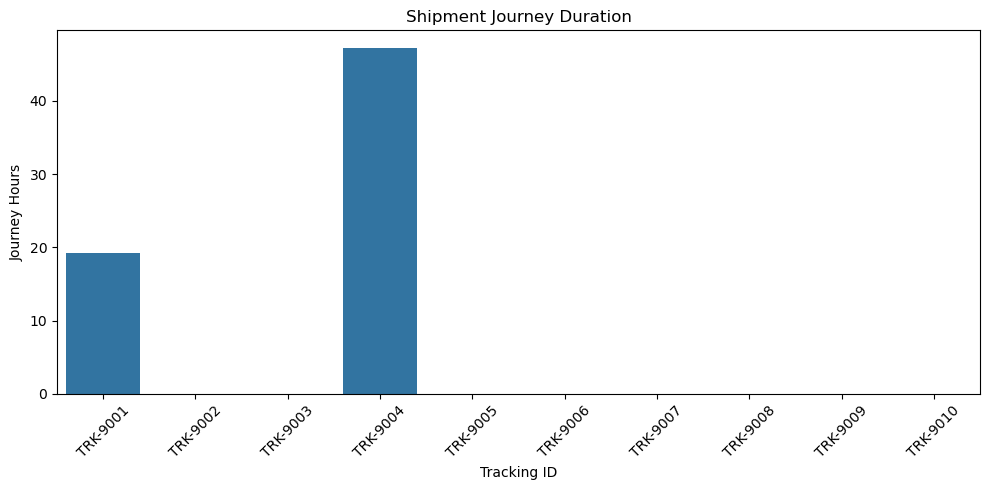

In [848]:
plt.figure(figsize=(10, 5))
sns.barplot(data=timeline.head(10),
            x='Tracking_ID', y='Journey_Hours')

plt.title("Shipment Journey Duration")
plt.xlabel("Tracking ID")
plt.ylabel("Journey Hours")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 12. Forecast parcel volume by depot and weekday using historical data.

In [849]:
df['Shipment_Date'] = pd.to_datetime(
    df['Shipment_Date'], errors='coerce'
)

In [850]:
df = df.dropna(subset=['Shipment_Date', 'Depot_Name', 'Shipment_ID'])

In [851]:
data = df.groupby(
    ['Depot_Name', 'Shipment_Date']
)['Shipment_ID'].nunique().reset_index(name='Parcel_Volume')

In [852]:
data['Weekday'] = data['Shipment_Date'].dt.day_name()

In [853]:
forecast = data.groupby(
    ['Depot_Name', 'Weekday']
)['Parcel_Volume'].mean().reset_index()

forecast['Forecast_Volume'] = np.round(
    forecast['Parcel_Volume']
).astype(int)

print(forecast)

           Depot_Name    Weekday  Parcel_Volume  Forecast_Volume
0     BERHAMPUR DEPOT     Friday            1.0                1
1     BERHAMPUR DEPOT     Monday            1.0                1
2     BERHAMPUR DEPOT   Saturday            1.0                1
3   BHUBANESWAR DEPOT     Monday            1.0                1
4   BHUBANESWAR DEPOT   Saturday            1.0                1
5   BHUBANESWAR DEPOT     Sunday            1.0                1
6   BHUBANESWAR DEPOT   Thursday            1.0                1
7          PURI DEPOT     Friday            1.0                1
8          PURI DEPOT     Sunday            1.0                1
9          PURI DEPOT    Tuesday            1.0                1
10         PURI DEPOT  Wednesday            1.0                1
11     ROURKELA DEPOT   Saturday            1.0                1
12     ROURKELA DEPOT  Wednesday            1.0                1
13    SAMBALPUR DEPOT     Friday            1.0                1
14    SAMBALPUR DEPOT    

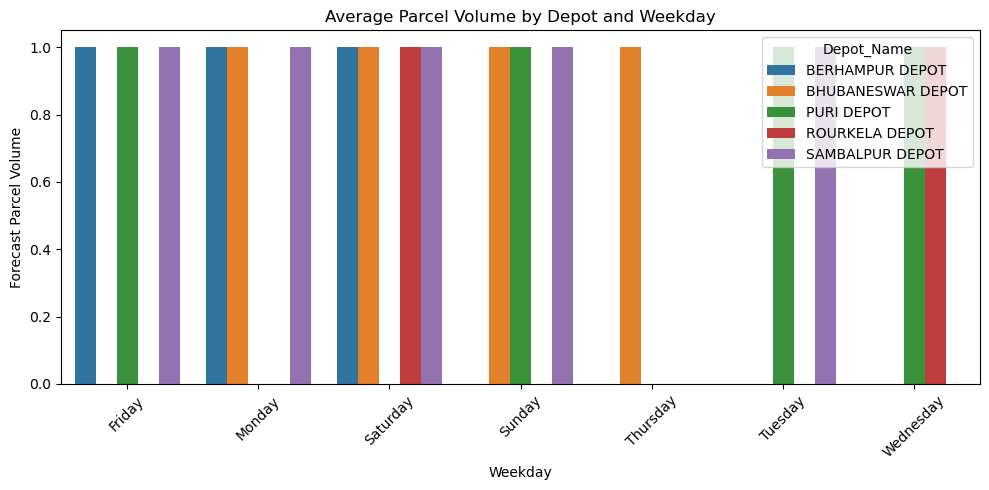

In [854]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=forecast,
    x='Weekday',
    y='Forecast_Volume',
    hue='Depot_Name',
    errorbar=None
)

plt.title('Average Parcel Volume by Depot and Weekday')
plt.xlabel('Weekday')
plt.ylabel('Forecast Parcel Volume')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [855]:
df['Event_Timestamp'] = pd.to_datetime(
    df['Event_Timestamp'], errors='coerce', utc=True
)

In [856]:
df = df.sort_values(['Tracking_ID', 'Event_Timestamp'])

In [857]:
df['Transit_Hours'] = (
    df.groupby('Tracking_ID')['Event_Timestamp']
    .diff().dt.total_seconds() / 3600
)

In [858]:
limit = df['Transit_Hours'].mean() + 2 * df['Transit_Hours'].std()
df['Transit_Outlier'] = df['Transit_Hours'] > limit


In [859]:
df['Exception_Flag'] = df['Exception_Code'].notna().astype(int)

daily = df.groupby(df['Event_Timestamp'].dt.date)['Exception_Flag'].sum()

Transit outliers:
Empty DataFrame
Columns: [Tracking_ID, Transit_Hours]
Index: []
Daily exceptions:
Event_Timestamp
2026-07-05    0
2026-07-08    0
2026-07-13    0
2026-07-14    0
2026-07-15    0
2026-07-17    0
2026-07-27    0
2026-08-18    0
2026-08-25    0
2026-08-26    0
2026-09-08    0
2026-09-16    0
2026-09-30    0
Name: Exception_Flag, dtype: int64


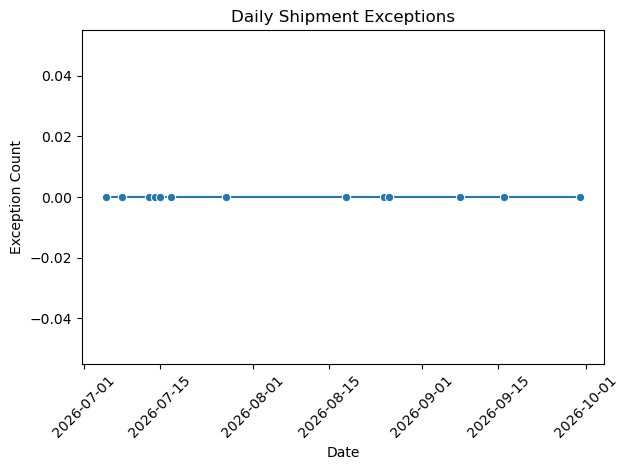

In [860]:
print("Transit outliers:")
print(df[df['Transit_Outlier']][['Tracking_ID', 'Transit_Hours']])

print("Daily exceptions:")
print(daily)

# Plot daily exceptions
sns.lineplot(x=daily.index, y=daily.values, marker='o')
plt.title("Daily Shipment Exceptions")
plt.xlabel("Date")
plt.ylabel("Exception Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



# 13. Detect outlier transit times, GPS jumps, and sudden exception spikes.

In [861]:

q1 = df["Actual_Transit_Time_Hours"].quantile(0.25)
q3 = df["Actual_Transit_Time_Hours"].quantile(0.75)
iqr = q3 - q1

outliers = df[df["Actual_Transit_Time_Hours"] > q3 + 1.5 * iqr]
print("Transit Time Outliers:")
print(outliers[["Shipment_ID", "Actual_Transit_Time_Hours"]])



Transit Time Outliers:
    Shipment_ID  Actual_Transit_Time_Hours
138  SHP-100030                      115.9


In [862]:
print("\nGPS Jumps:")
print(df[df["GPS_Jump"] == True][["Shipment_ID", "GPS_Jump"]])



GPS Jumps:
    Shipment_ID  GPS_Jump
302  SHP-100063      True


In [863]:
df["Event_Timestamp"] = pd.to_datetime(df["Event_Timestamp"], utc=True, errors="coerce")

df["Exception"] = df["Exception_Flag"].astype(str).str.lower().isin(["yes", "y", "true", "1"])

daily = df.groupby(df["Event_Timestamp"].dt.date)["Exception"].sum()


In [864]:
print("Daily Exceptions:")
print(daily)

print("\nException Spikes:")
print(daily[daily > daily.mean() + 2 * daily.std()])

Daily Exceptions:
Event_Timestamp
2026-07-05    0
2026-07-08    0
2026-07-13    0
2026-07-14    0
2026-07-15    0
2026-07-17    0
2026-07-27    0
2026-08-18    0
2026-08-25    0
2026-08-26    0
2026-09-08    0
2026-09-16    0
2026-09-30    0
Name: Exception, dtype: int64

Exception Spikes:
Series([], Name: Exception, dtype: int64)


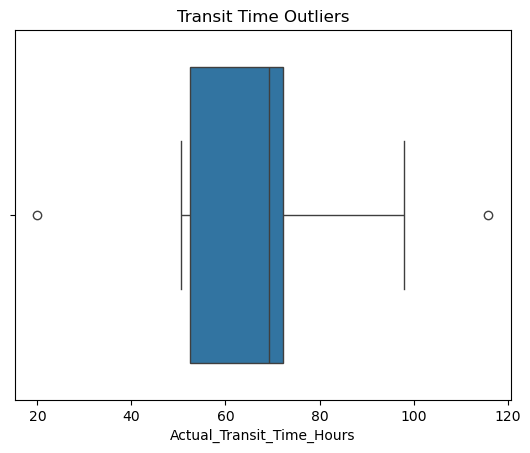

In [865]:
sns.boxplot(x=df["Actual_Transit_Time_Hours"])
plt.title("Transit Time Outliers")
plt.show()

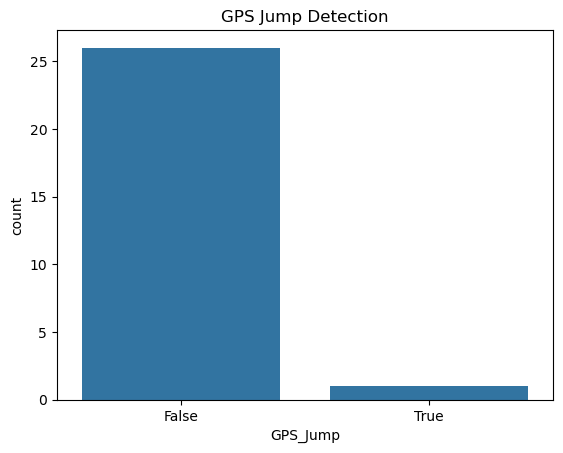

In [866]:
sns.countplot(data=df, x="GPS_Jump")
plt.title("GPS Jump Detection")
plt.show()

# 14. Build carrier scorecards with consistent denominator and service-level definitions.

In [867]:

df["Carrier"] = df["Carrier_Name"].str.upper().str.replace(
    r"[^A-Z0-9]", "", regex=True
)

In [868]:
df["Actual"] = pd.to_datetime(df["Actual_Delivery_Timestamp"], format="mixed", utc=True, errors="coerce")
df["Promised"] = pd.to_datetime(df["Promised_Delivery_Timestamp"], format="mixed", utc=True, errors="coerce")


In [869]:
df["Exception"] = df["Exception_Flag"].astype(str).str.lower().isin(["yes", "y", "true", "1"])


In [870]:
ship = df.groupby("Shipment_ID").agg(
    Carrier=("Carrier", "first"),
    Actual=("Actual", "max"),
    Promised=("Promised", "first"),
    Transit=("Actual_Transit_Time_Hours", "max"),
    Exception=("Exception", "max")
).reset_index()


In [871]:
ship["On_Time"] = ship["Actual"] <= ship["Promised"]


In [872]:
score = ship.groupby("Carrier").agg(
    Shipments=("Shipment_ID", "count"),
    Exceptions=("Exception", "sum"),
    Avg_Transit=("Transit", "mean"),
    On_Time=("On_Time", "mean")
)
score["Exception_Rate"] = ship.groupby("Carrier")["Exception"].mean() * 100
score["On_Time_Rate"] = ship.groupby("Carrier")["On_Time"].mean() * 100


In [873]:
print(score.round(2))

           Shipments  Exceptions  Avg_Transit  On_Time  Exception_Rate  \
Carrier                                                                  
FASTSHIP           5           0        63.77     0.20             0.0   
GREENLINE          8           0        58.20     0.25             0.0   
ROADX              3           0        67.95     0.00             0.0   
SWIFTPOST          8           0        73.35     0.12             0.0   

           On_Time_Rate  
Carrier                  
FASTSHIP           20.0  
GREENLINE          25.0  
ROADX               0.0  
SWIFTPOST          12.5  


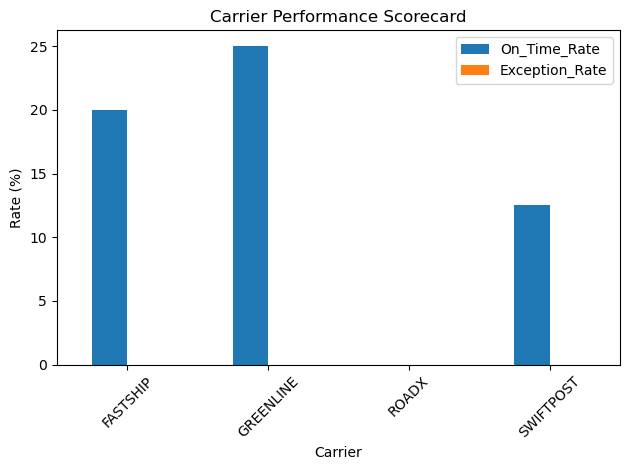

In [874]:
score[["On_Time_Rate", "Exception_Rate"]].plot(kind="bar")

plt.title("Carrier Performance Scorecard")
plt.ylabel("Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 15. Calculate COD collection and reconciliation metrics where relevant.

In [875]:

cols = ["COD_Amount", "COD_Collected_Amount",
        "Outstanding_COD_Amount", "Remittance_Amount"]

for col in cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(r"[^\d.-]", "", regex=True),
        errors="coerce"
    )



In [876]:
cod = df[df["COD_Flag"].astype(str).str.lower().isin(
    ["yes", "y", "true", "1"]
)]

In [877]:
cod = cod.groupby("Shipment_ID").first()


In [878]:
print("Total COD Amount:", cod["COD_Amount"].sum())
print("Amount Collected:", cod["COD_Collected_Amount"].sum())
print("Outstanding COD:", cod["Outstanding_COD_Amount"].sum())
print("Total Remittance:", cod["Remittance_Amount"].sum())

print("Collection Rate (%):",
      round(cod["COD_Collected_Amount"].sum() /
            cod["COD_Amount"].sum() * 100, 2))

print("Reconciled Shipments:",
      cod["Reconciliation_Status"].astype(str).str.lower()
      .isin(["reconciled", "recon"]).sum())

Total COD Amount: 0.0
Amount Collected: 15877.0
Outstanding COD: 0.0
Total Remittance: 15877.0
Collection Rate (%): inf
Reconciled Shipments: 2


C:\Users\HP\AppData\Local\Temp\ipykernel_10868\2708746472.py:7: RuntimeWarning: divide by zero encountered in scalar divide
  round(cod["COD_Collected_Amount"].sum() /


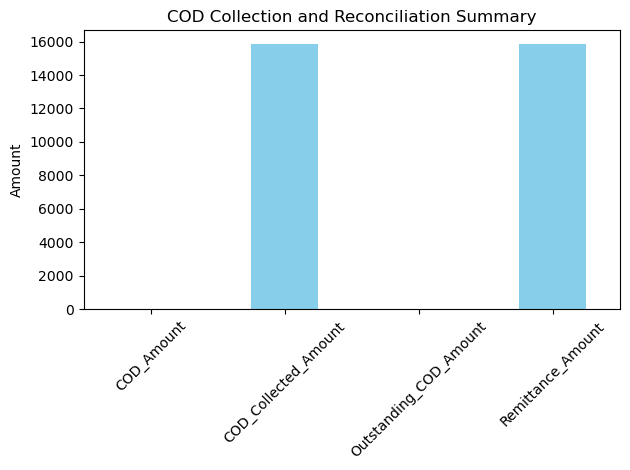

In [879]:

cod[cols].sum().plot(kind="bar", color="skyblue")

plt.title("COD Collection and Reconciliation Summary")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 16. Produce privacy-safe operational dashboards without full customer addresses or phone numbers.

In [880]:

private_cols = ["Customer_Address", "Customer_Phone"]

safe_df = df.drop(columns=private_cols, errors="ignore")

In [881]:
print("Total Shipments:", safe_df["Shipment_ID"].nunique())
print("\nShipments by Status:")
print(safe_df["Parcel_Status"].value_counts())

print("\nShipments by Depot:")
print(safe_df.groupby("Depot_Name")["Shipment_ID"].nunique())

Total Shipments: 24

Shipments by Status:
Parcel_Status
In Network        8
Delivered         6
  In Network      4
Delivered         2
DELIVERED         2
In Network        2
  Delivered       1
 Delivered        1
 In Network       1
Name: count, dtype: int64

Shipments by Depot:
Depot_Name
BERHAMPUR DEPOT      5
BHUBANESWAR DEPOT    6
PURI DEPOT           4
ROURKELA DEPOT       3
SAMBALPUR DEPOT      6
Name: Shipment_ID, dtype: int64


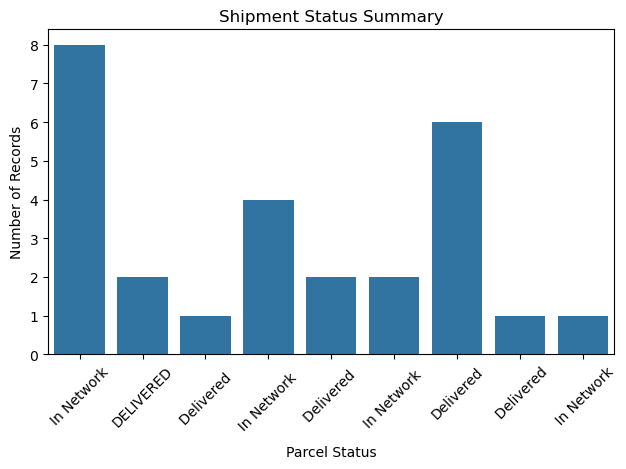

In [882]:

sns.countplot(data=safe_df, x="Parcel_Status")

plt.title("Shipment Status Summary")
plt.xlabel("Parcel Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()